<a href="https://colab.research.google.com/github/emilianomtz0189/credit-risk-scorecard/blob/main/notebooks/06_metricas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 06 · Métricas de la industria: AUC, Gini, KS y estabilidad

**Objetivo:** medir, en la **muestra de prueba** (clientes que ningún modelo vio), qué tan bien separan el scorecard y LightGBM a los clientes buenos de los malos, y si el scorecard es estable.

## Conceptos

### AUC (área bajo la curva ROC)
Si se toma al azar un cliente malo y uno bueno, el AUC es la **probabilidad de que el modelo le asigne más riesgo al malo**.
- 0.5 = igual que lanzar una moneda.
- 1.0 = separación perfecta.
- Como referencia general (Hosmer y Lemeshow): 0.7–0.8 aceptable, 0.8–0.9 excelente, más de 0.9 sobresaliente.

### Gini
Es el AUC reescalado: **Gini = 2 × AUC − 1**. Va de 0 (al azar) a 1 (perfecto). Es la métrica más usada en bancos para reportar el poder de un scorecard.

### KS (Kolmogorov-Smirnov)
Se ordenan los clientes por puntaje y se acumulan, por separado, el % de malos y el % de buenos. El KS es la **mayor distancia entre esas dos curvas**: el punto del puntaje donde el modelo mejor separa a los malos de los buenos. Se usa mucho para elegir puntos de corte.

### PSI (*Population Stability Index*, índice de estabilidad)
Compara cómo se distribuyen los clientes entre dos muestras (por ejemplo, entrenamiento contra prueba, o el mes de desarrollo contra el mes actual). Detecta si la población cambió y el modelo podría dejar de funcionar.

| PSI | Interpretación |
|---|---|
| Menos de 0.10 | Estable |
| 0.10 a 0.25 | Revisar |
| Más de 0.25 | Inestable: el modelo probablemente necesita recalibrarse |

## Entorno

In [1]:
import os
import sys
from pathlib import Path

USUARIO_GITHUB = "emilianomtz0189"
NOMBRE_REPO = "credit-risk-scorecard"
CARPETA_DRIVE = Path("/content/drive/MyDrive/credit-risk-scorecard")  # Donde está cs-training.csv

EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

    ruta_repo = Path("/content") / NOMBRE_REPO
    if not ruta_repo.exists():
        !git clone -q https://github.com/{USUARIO_GITHUB}/{NOMBRE_REPO}.git {ruta_repo}
    else:
        !git -C {ruta_repo} pull -q
    os.chdir(ruta_repo)
elif Path.cwd().name == "notebooks":
    os.chdir("..")

sys.path.insert(0, str(Path.cwd()))
print("Directorio de trabajo:", Path.cwd())

Mounted at /content/drive
Directorio de trabajo: /content/credit-risk-scorecard


In [2]:
!pip install -q -r requirements.txt

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src import config
from src.comparacion import construir_modelo_comparacion
from src.datos import copiar_datos_crudos
from src.limpieza import obtener_datos_limpios
from src.metricas import (
    bootstrap_diferencia_auc,
    estabilidad,
    graficar_ks,
    graficar_roc,
    psi_puntaje,
    psi_variables,
    tabla_deciles,
    tabla_metricas,
)
from src.scorecard import construir_scorecard

config.fijar_semilla()
config.crear_carpetas()
pd.set_option("display.float_format", "{:,.4f}".format)

In [4]:
# Reconstruye ambos modelos de las etapas 4 y 5 (deterministas). Tarda unos minutos.
copiar_datos_crudos(CARPETA_DRIVE)
train, test = obtener_datos_limpios()
Y = config.COLUMNA_OBJETIVO

scorecard = construir_scorecard()
lightgbm = construir_modelo_comparacion()

puntaje_train = scorecard["puntaje_train"]["puntaje"]
puntaje_test = scorecard["puntaje_test"]["puntaje"]
print("Modelos listos.")

Copiado cs-training.csv a data/raw/cs-training.csv
Modelos listos.


## 1. AUC, Gini y KS de ambos modelos

Para el scorecard se usa el puntaje con signo negativo, porque en las métricas "mayor valor = mayor riesgo". Se calculan en entrenamiento y en prueba: si un modelo es mucho mejor en entrenamiento que en prueba, está **sobreajustado** (memorizó en lugar de aprender).

In [5]:
resultados = tabla_metricas({
    ("Scorecard", "entrenamiento"): (train[Y], -puntaje_train),
    ("Scorecard", "prueba"): (test[Y], -puntaje_test),
    ("LightGBM", "entrenamiento"): (train[Y], lightgbm["pd_train"]),
    ("LightGBM", "prueba"): (test[Y], lightgbm["pd_test"]),
})
resultados

auc   gini     ks
modelo    muestra                           
Scorecard entrenamiento 0.8584 0.7167 0.5570
          prueba        0.8569 0.7137 0.5629
LightGBM  entrenamiento 0.8775 0.7549 0.5978
          prueba        0.8661 0.7323 0.5777

In [6]:
# Diferencia entre entrenamiento y prueba (sobreajuste)
brecha = (resultados.xs("entrenamiento", level="muestra") - resultados.xs("prueba", level="muestra"))
brecha.columns = [f"{c}_entrenamiento_menos_prueba" for c in brecha.columns]
brecha

,auc_entrenamiento_menos_prueba,gini_entrenamiento_menos_prueba,ks_entrenamiento_menos_prueba
modelo,,,
Scorecard,0.0015,0.0030,-0.0059
LightGBM,0.0113,0.0227,0.0202


### ¿La diferencia entre modelos es real o casualidad?

Se remuestrean los clientes de prueba 300 veces (*bootstrap*) y se calcula la diferencia de AUC en cada repetición. Si el intervalo de 95 % no incluye el cero, la diferencia es estadísticamente significativa. Después hay que preguntarse si también es **relevante para el negocio**.

In [7]:
diferencia = bootstrap_diferencia_auc(test[Y], -puntaje_test, lightgbm["pd_test"])
print("AUC LightGBM − AUC scorecard, en prueba:")
diferencia

AUC LightGBM − AUC scorecard, en prueba:


,0
diferencia_auc,0.0093
limite_inferior_95,0.0074
limite_superior_95,0.0114


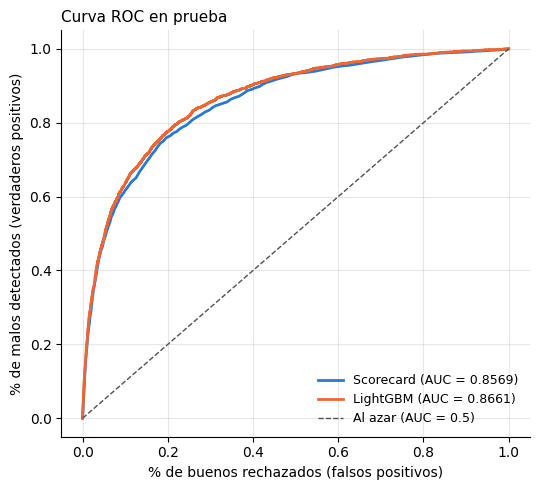

In [8]:
graficar_roc({
    "Scorecard": (test[Y], -puntaje_test),
    "LightGBM": (test[Y], lightgbm["pd_test"]),
})
plt.show()

**Cómo leer la curva ROC:** cada punto es un posible punto de corte. El eje horizontal es el % de clientes buenos que se rechazarían y el vertical, el % de malos que se detectarían. Mientras más se acerque la curva a la esquina superior izquierda, mejor. La diagonal punteada es un modelo al azar.

## 2. KS del scorecard

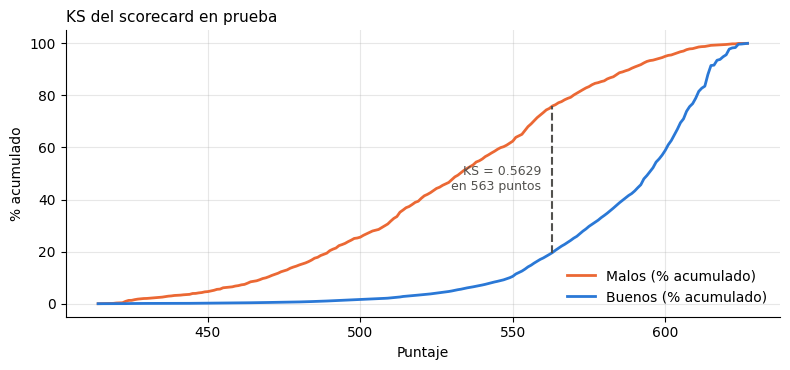

In [9]:
graficar_ks(test[Y], puntaje_test)
plt.show()

## 3. Tabla de deciles (tabla de ganancias)

Se ordena a los clientes de prueba del más riesgoso al menos riesgoso y se divide en 10 grupos iguales. La columna clave es `pct_malos_acum`: **qué porcentaje de todos los malos se concentra en los clientes más riesgosos**. Es la tabla que se presenta a la dirección para decidir a cuántos clientes rechazar o revisar.

In [10]:
print("Scorecard (prueba)")
deciles_scorecard = tabla_deciles(test[Y], -puntaje_test)
display(deciles_scorecard)

print("LightGBM (prueba)")
deciles_lgb = tabla_deciles(test[Y], lightgbm["pd_test"])
display(deciles_lgb)

Scorecard (prueba)


,clientes,malos,buenos,tasa_malos,pct_malos_acum,pct_buenos_acum,ks
decil (1 = más riesgo),,,,,,,
1,4500,1641,2859,0.3647,0.5455,0.0681,0.4775
2,4500,510,3990,0.1133,0.7151,0.1631,0.5520
3,4500,292,4208,0.0649,0.8122,0.2633,0.5489
4,4500,176,4324,0.0391,0.8707,0.3663,0.5044
5,4500,152,4348,0.0338,0.9212,0.4698,0.4514
6,4500,77,4423,0.0171,0.9468,0.5752,0.3717
7,4500,55,4445,0.0122,0.9651,0.6810,0.2841
8,4500,50,4450,0.0111,0.9817,0.7870,0.1947
9,4500,29,4471,0.0064,0.9914,0.8935,0.0979


LightGBM (prueba)


,clientes,malos,buenos,tasa_malos,pct_malos_acum,pct_buenos_acum,ks
decil (1 = más riesgo),,,,,,,
1,4500,1687,2813,0.3749,0.5608,0.0670,0.4938
2,4500,512,3988,0.1138,0.7311,0.1620,0.5691
3,4500,309,4191,0.0687,0.8338,0.2618,0.5720
4,4500,163,4337,0.0362,0.8880,0.3650,0.5229
5,4500,116,4384,0.0258,0.9265,0.4694,0.4571
6,4500,77,4423,0.0171,0.9521,0.5748,0.3774
7,4500,59,4441,0.0131,0.9717,0.6805,0.2912
8,4500,40,4460,0.0089,0.9850,0.7867,0.1983
9,4500,28,4472,0.0062,0.9943,0.8932,0.1011


In [11]:
captura = pd.DataFrame({
    "scorecard": deciles_scorecard["pct_malos_acum"],
    "lightgbm": deciles_lgb["pct_malos_acum"],
})
captura.index.name = "% de clientes más riesgosos"
captura.index = [f"{d * 10} %" for d in captura.index]
print("% de todos los malos capturados al revisar al X % de clientes más riesgosos:")
captura

% de todos los malos capturados al revisar al X % de clientes más riesgosos:


,scorecard,lightgbm
10 %,0.5455,0.5608
20 %,0.7151,0.7311
30 %,0.8122,0.8338
40 %,0.8707,0.8880
50 %,0.9212,0.9265
60 %,0.9468,0.9521
70 %,0.9651,0.9717
80 %,0.9817,0.9850
90 %,0.9914,0.9943
100 %,1.0000,1.0000


## 4. Estabilidad del scorecard (PSI)

Se compara la distribución de **entrenamiento** (la "población de desarrollo") con la de **prueba**. Como ambas vienen de la misma base y se separaron al azar, se espera estabilidad; el valor de este análisis es dejar el procedimiento listo para monitorear el modelo cada mes cuando esté en producción.

In [12]:
psi_total, distribucion = psi_puntaje(puntaje_train, puntaje_test)
print(f"PSI del puntaje: {psi_total:.4f} ({estabilidad(psi_total)})")
distribucion

PSI del puntaje: 0.0003 (Estable)


,pct_entrenamiento,pct_prueba
rango_puntaje,,
"(-inf, 538.0]",0.1010,0.0990
"(538.0, 558.0]",0.1009,0.1007
"(558.0, 572.0]",0.1051,0.1058
"(572.0, 583.0]",0.0966,0.0954
"(583.0, 593.0]",0.1045,0.1084
"(593.0, 600.0]",0.1037,0.1035
"(600.0, 605.0]",0.1024,0.1004
"(605.0, 610.0]",0.0885,0.0889
"(610.0, 615.0]",0.1153,0.1177


In [13]:
# PSI por variable (también llamado CSI): estabilidad de cada característica del scorecard
psi_variables(scorecard["agrupador"], train, test, scorecard["variables"])

,psi,estabilidad
variable,,
uso_credito_revolvente,0.0003,Estable
razon_deuda,0.0003,Estable
edad,0.0002,Estable
atrasos_90,0.0001,Estable
num_creditos_inmobiliarios,0.0001,Estable
num_dependientes,0.0001,Estable
atrasos_30_59,0.0000,Estable
atrasos_60_89,0.0000,Estable


## Hallazgos de la etapa

- **Poder predictivo en prueba:** scorecard con AUC de 0.8569, Gini de 0.7137 y KS de 0.5629; LightGBM con AUC de 0.8661, Gini de 0.7323 y KS de 0.5777. Ambos están en el rango "excelente" (AUC entre 0.8 y 0.9).
- **Sobreajuste:** el scorecard casi no cambia entre entrenamiento y prueba (AUC 0.8584 vs. 0.8569, diferencia de 0.0015). LightGBM baja más (0.8775 vs. 0.8661, diferencia de 0.0113): aprendió algo de ruido de entrenamiento. El scorecard es más robusto.
- **Diferencia entre modelos:** LightGBM supera al scorecard por 0.0093 de AUC en prueba, con intervalo de confianza de 95 % entre 0.0074 y 0.0114. La diferencia es estadísticamente significativa pero pequeña: equivale a menos de 2 puntos de Gini.
- **KS del scorecard:** la mayor separación entre malos y buenos está en 563 puntos, una referencia natural para los puntos de corte de la etapa 7.
- **Concentración del riesgo:** revisando al 10 % de clientes con menor puntaje se captura el 54.55 % de todos los malos (56.08 % con LightGBM); con el 20 %, el 71.51 % (73.11 %); con el 30 %, el 81.22 % (83.38 %). La tasa de malos va de 36.47 % en el decil más riesgoso a 0.58 % en el menos riesgoso.
- **Estabilidad:** el PSI del puntaje entre entrenamiento y prueba es de 0.0003, y el de cada variable no pasa de 0.0003: todo estable (el umbral de alerta es 0.10).
- **Conclusión:** LightGBM gana menos de 2 puntos de Gini a cambio de perder la explicabilidad y de sobreajustar más. **Se recomienda el scorecard como modelo principal**; LightGBM puede quedar como modelo retador (*challenger*) para monitorear si en el futuro la brecha crece.

## Resumen de la etapa

- Se midieron AUC, Gini y KS del scorecard y de LightGBM en entrenamiento y prueba.
- Se probó si la diferencia entre modelos es estadísticamente significativa (bootstrap).
- Se construyó la tabla de deciles: qué porcentaje de malos se concentra en los clientes más riesgosos.
- Se revisó la estabilidad del puntaje y de cada variable con el PSI.

**Siguiente paso:** notebook `07_perdida_esperada.ipynb`, pérdida esperada (PD × LGD × EAD) y propuesta de puntos de corte.